<a href="https://colab.research.google.com/github/SShruthikeerthana/Healthcare_analysis/blob/main/Healthcare_risk_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [7]:
from google.colab import files

uploaded = files.upload()

Saving diabetes.csv to diabetes.csv


In [8]:
import pandas as pd

df = pd.read_csv("diabetes.csv")

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72.0,35,169.5,33.6,0.627,50,1
1,1,85,66.0,29,102.5,26.6,0.351,31,0
2,8,183,64.0,32,169.5,23.3,0.672,32,1
3,1,89,66.0,23,94.0,28.1,0.167,21,0
4,0,137,40.0,35,168.0,43.1,2.288,33,1


In [9]:
print("Columns:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

Columns:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    float64
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    float64
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(4), int64(5)
memory usage: 54.1 KB

Statistical Summary:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,121.677083,72.389323,29.089844,141.753906,32.434635,0.471876,33.240885,0.348958
std,3.369578,30.464161,12.106039,8.890820,89.100847,6.880498,0.331329,11.760232,0.476951
min,0.000000,44.000000,24.000000,7.000000,14.000000,18.200000,0.078000,21.000000,0.000000
25%,1.000000,99.750000,64.000000,25.000000,102.500000,27.500000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,28.000000,102.500000,32.050000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,169.500000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [10]:
zero_columns = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

print("Zero values in important clinical columns:\n")

for col in zero_columns:
    print(col, ":", (df[col] == 0).sum())

Zero values in important clinical columns:

Glucose : 0
BloodPressure : 0
SkinThickness : 0
Insulin : 0
BMI : 0


In [11]:
for col in zero_columns:
    df[col] = df[col].replace(0, df[col].median())

print("Zero-value cleaning completed.")

print("\nRemaining zero values:")
for col in zero_columns:
    print(col, ":", (df[col] == 0).sum())

Zero-value cleaning completed.

Remaining zero values:
Glucose : 0
BloodPressure : 0
SkinThickness : 0
Insulin : 0
BMI : 0


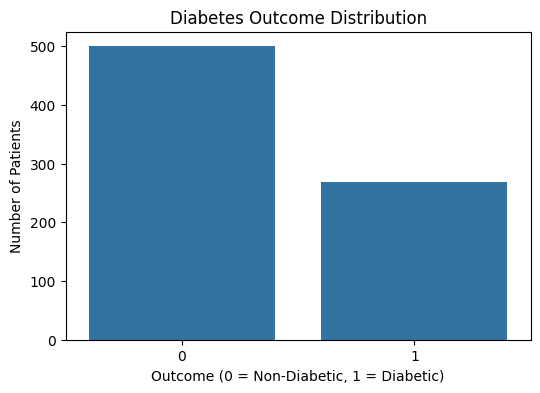

In [12]:

plt.figure(figsize=(6, 4))

sns.countplot(x='Outcome', data=df)

plt.title("Diabetes Outcome Distribution")
plt.xlabel("Outcome (0 = Non-Diabetic, 1 = Diabetic)")
plt.ylabel("Number of Patients")

plt.show()

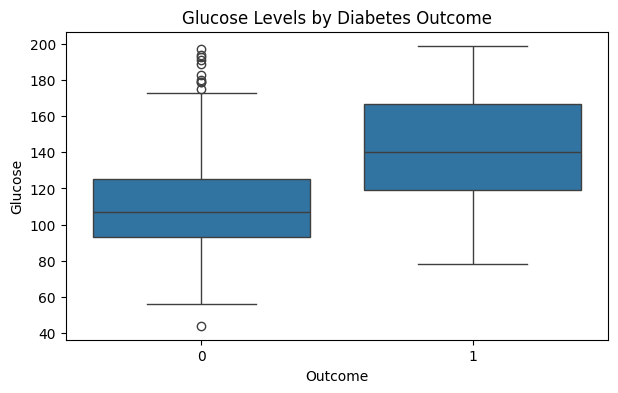

In [13]:
plt.figure(figsize=(7, 4))

sns.boxplot(x='Outcome', y='Glucose', data=df)

plt.title("Glucose Levels by Diabetes Outcome")
plt.xlabel("Outcome")
plt.ylabel("Glucose")

plt.show()

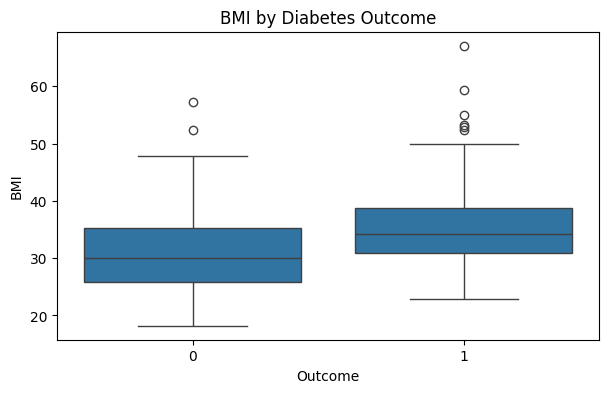

In [14]:
plt.figure(figsize=(7, 4))

sns.boxplot(x='Outcome', y='BMI', data=df)

plt.title("BMI by Diabetes Outcome")
plt.xlabel("Outcome")
plt.ylabel("BMI")

plt.show()

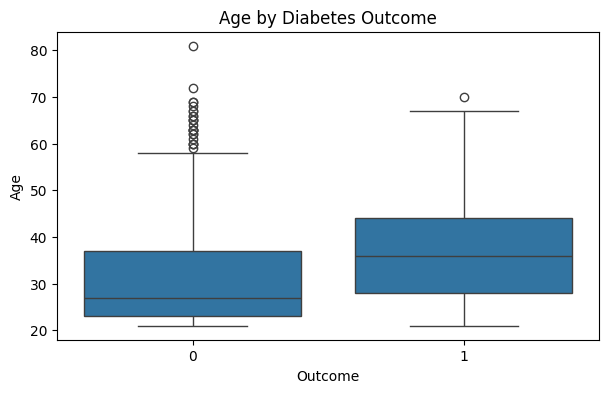

In [15]:
plt.figure(figsize=(7, 4))

sns.boxplot(x='Outcome', y='Age', data=df)

plt.title("Age by Diabetes Outcome")
plt.xlabel("Outcome")
plt.ylabel("Age")

plt.show()

Correlation with Outcome:
Outcome                     1.000000
Glucose                     0.495990
Insulin                     0.377081
BMI                         0.315577
SkinThickness               0.295138
Age                         0.238356
Pregnancies                 0.221898
BloodPressure               0.174469
DiabetesPedigreeFunction    0.173844
Name: Outcome, dtype: float64


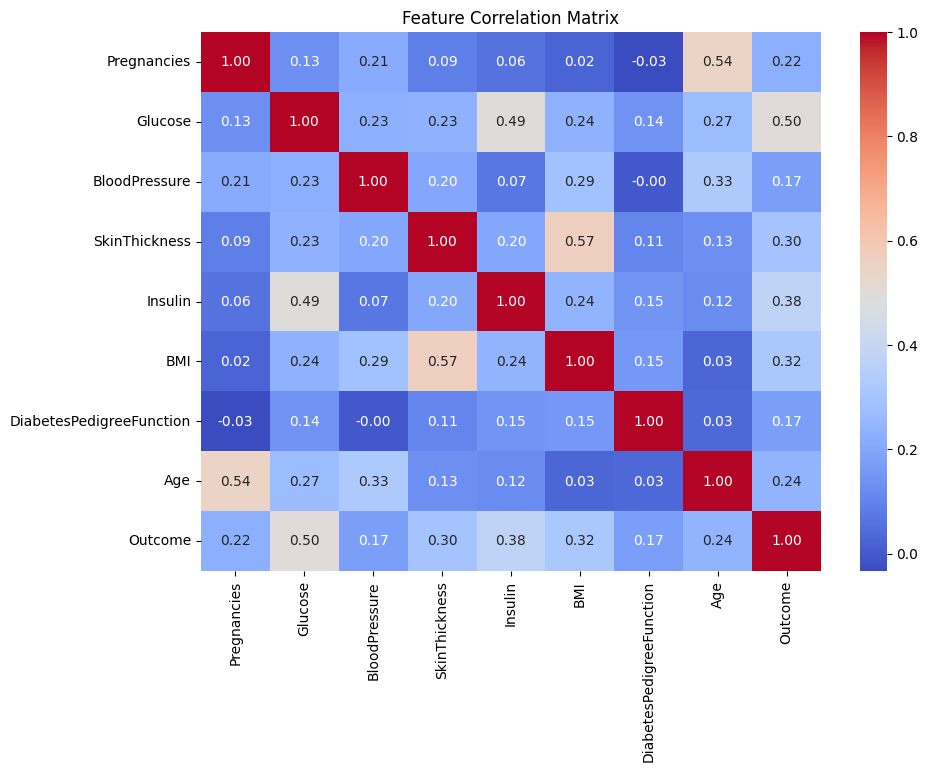

In [16]:
correlation = df.corr()

print("Correlation with Outcome:")
print(
    correlation['Outcome']
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Feature Correlation Matrix")
plt.show()

In [17]:
X = df.drop('Outcome', axis=1)
y = df['Outcome']

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print("Outcome")

Features:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']

Target:
Outcome


In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])

Training samples: 614
Testing samples : 154


In [19]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


In [20]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [21]:
y_pred = model.predict(X_test_scaled)

print("Predictions generated successfully.")

Predictions generated successfully.


In [22]:
accuracy = accuracy_score(y_test, y_pred)

print(f"Test Accuracy: {accuracy:.2%}")

Test Accuracy: 70.78%


Confusion Matrix:
[[79 21]
 [24 30]]


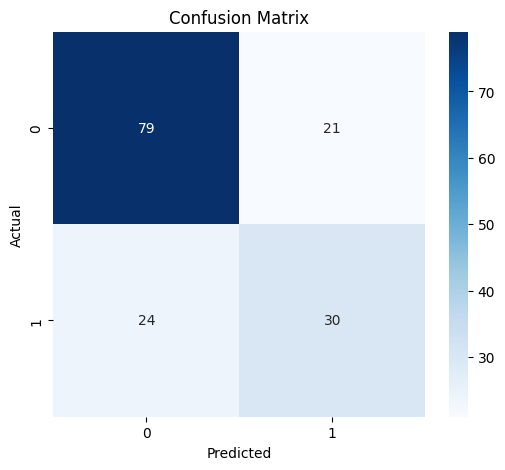

In [23]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [24]:
print("Classification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=['Non-Diabetic', 'Diabetic']
    )
)

Classification Report:
              precision    recall  f1-score   support

Non-Diabetic       0.77      0.79      0.78       100
    Diabetic       0.59      0.56      0.57        54

    accuracy                           0.71       154
   macro avg       0.68      0.67      0.67       154
weighted avg       0.70      0.71      0.71       154



In [25]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000))
])

print("Pipeline created.")

Pipeline created.


In [26]:
cv_scores = cross_val_score(
    pipeline,
    X,
    y,
    cv=5,
    scoring='accuracy'
)

print("5-Fold Cross-Validation Scores:")

for i, score in enumerate(cv_scores, start=1):
    print(f"Fold {i}: {score:.4f}")

print("\nMean CV Accuracy:", round(cv_scores.mean(), 4))
print("Standard Deviation:", round(cv_scores.std(), 4))

5-Fold Cross-Validation Scores:
Fold 1: 0.7662
Fold 2: 0.7403
Fold 3: 0.8052
Fold 4: 0.8039
Fold 5: 0.7778

Mean CV Accuracy: 0.7787
Standard Deviation: 0.0244


In [27]:
importance = pd.Series(
    abs(model.coef_[0]),
    index=X.columns
).sort_values(ascending=True)

print("Feature Importance:")
print(importance.sort_values(ascending=False))

Feature Importance:
Glucose                     0.934942
Insulin                     0.614170
BMI                         0.466051
Pregnancies                 0.337228
SkinThickness               0.294976
DiabetesPedigreeFunction    0.174725
Age                         0.159826
BloodPressure               0.004245
dtype: float64


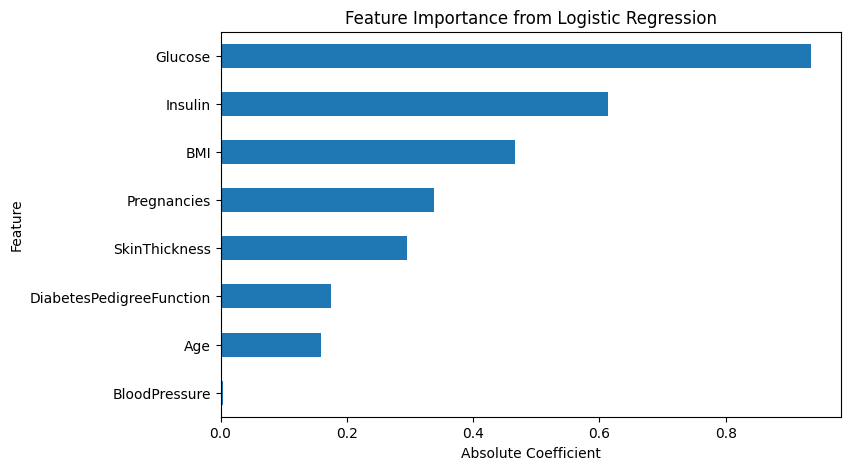

In [28]:
plt.figure(figsize=(8, 5))

importance.plot(kind='barh')

plt.title("Feature Importance from Logistic Regression")
plt.xlabel("Absolute Coefficient")
plt.ylabel("Feature")

plt.show()

In [29]:
def rule_based(glucose, bmi, age):

    if glucose > 150 and bmi > 30 and age > 45:
        return "High Risk"

    elif glucose > 120:
        return "Moderate Risk"

    else:
        return "Low Risk"

In [30]:
def predict_patient(data):

    input_df = pd.DataFrame(
        [data],
        columns=X.columns
    )

    # Scale using scaler fitted only on training data
    input_scaled = scaler.transform(input_df)

    # ML prediction
    prediction = model.predict(input_scaled)[0]

    # Probability of class 1
    probability = model.predict_proba(input_scaled)[0][1]

    # Risk category
    if probability >= 0.70:
        risk_level = "High Risk"

    elif probability >= 0.40:
        risk_level = "Moderate Risk"

    else:
        risk_level = "Low Risk"

    # Simple rule-based result
    rule_result = rule_based(
        data[1],   # Glucose
        data[5],   # BMI
        data[7]    # Age
    )

    # Recommendation
    if risk_level == "High Risk":
        recommendation = (
            "Consult a qualified healthcare professional "
            "for further evaluation."
        )

    elif risk_level == "Moderate Risk":
        recommendation = (
            "Consider lifestyle improvements and "
            "professional health screening."
        )

    else:
        recommendation = (
            "Maintain a healthy lifestyle and "
            "regular health monitoring."
        )

    print("\n" + "=" * 45)
    print("        PATIENT RISK REPORT")
    print("=" * 45)

    print(
        f"ML Prediction      : "
        f"{'Diabetic' if prediction == 1 else 'Non-Diabetic'}"
    )

    print(
        f"Risk Probability   : "
        f"{probability * 100:.2f}%"
    )

    print(f"Risk Level         : {risk_level}")

    print(f"Rule-Based Result  : {rule_result}")

    print(f"Recommendation     : {recommendation}")

    print("=" * 45)

In [31]:
sample_patient = [
    2,      # Pregnancies
    150,    # Glucose
    80,     # BloodPressure
    25,     # SkinThickness
    100,    # Insulin
    32,     # BMI
    0.5,    # DiabetesPedigreeFunction
    45      # Age
]

predict_patient(sample_patient)


        PATIENT RISK REPORT
ML Prediction      : Non-Diabetic
Risk Probability   : 38.24%
Risk Level         : Low Risk
Rule-Based Result  : Moderate Risk
Recommendation     : Maintain a healthy lifestyle and regular health monitoring.
